<a href="https://colab.research.google.com/github/mukilarasiu2025cse/FUNDAMENTAL-OF-DATA-SCIENCE-CS23334/blob/main/Reg_No_250701457_Name_Mukil_Arasi_U_Exp_No_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First five rows:
             Page_Views  Unique_Visitors  Bounce_Rate
Date                                                 
2025-01-01  1024.835708       684.913230    46.038693
2025-01-02  1112.361507       697.320253    51.974635
2025-01-03  1182.623614       736.578574    49.657119
2025-01-04  1147.234054       760.176307    47.972842
2025-01-05   931.209770       598.582467    44.210869

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 180 entries, 2025-01-01 to 2025-06-29
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Page_Views       180 non-null    float64
 1   Unique_Visitors  180 non-null    float64
 2   Bounce_Rate      180 non-null    float64
dtypes: float64(3)
memory usage: 5.6 KB

Dataset Shape:
(180, 3)

Missing Values:
Page_Views         0
Unique_Visitors    0
Bounce_Rate        0
dtype: int64

Statistical Summary:
        Page_Views  Unique_Visitors  Bounce_Rate
c

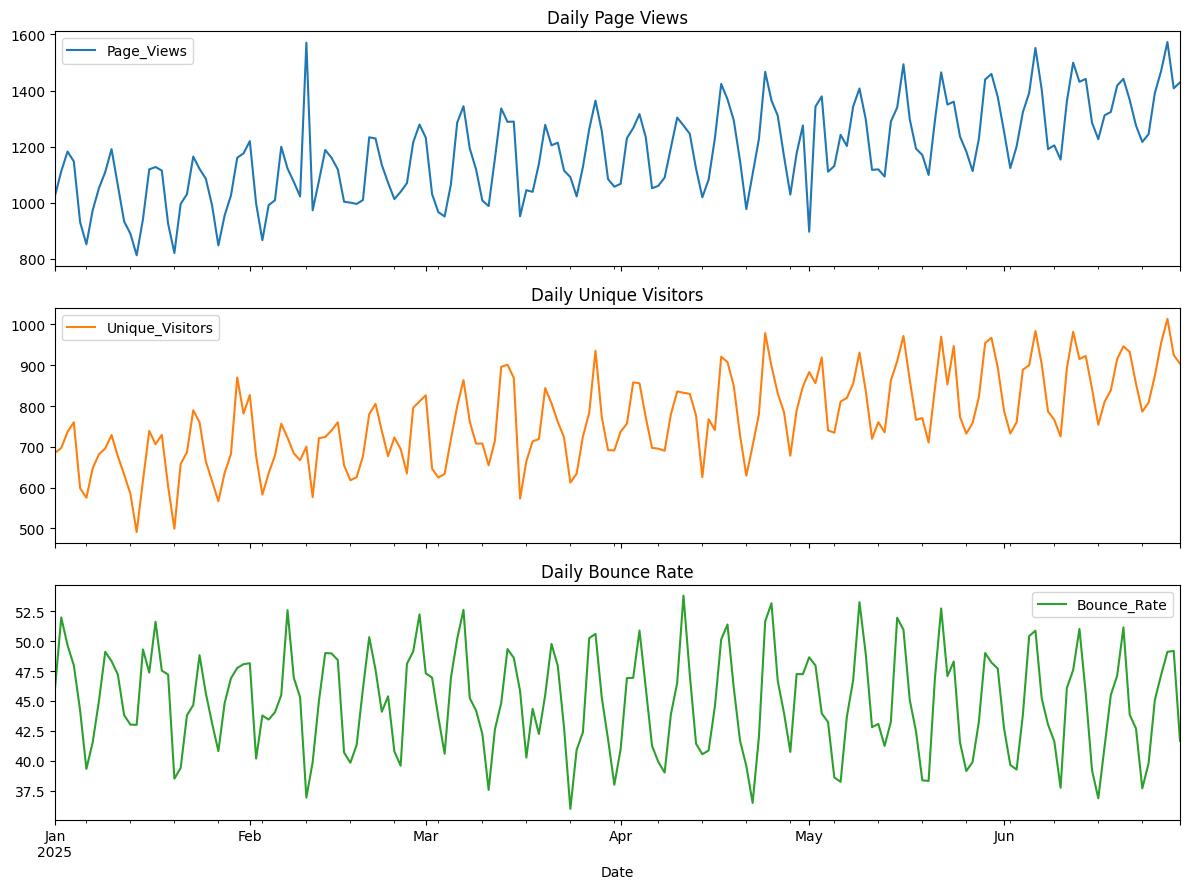

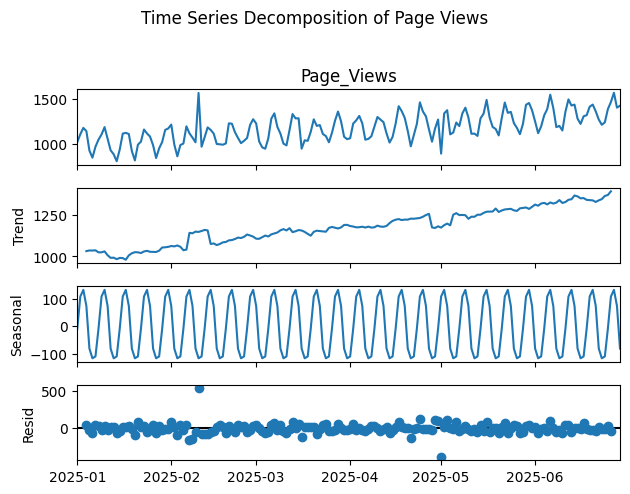

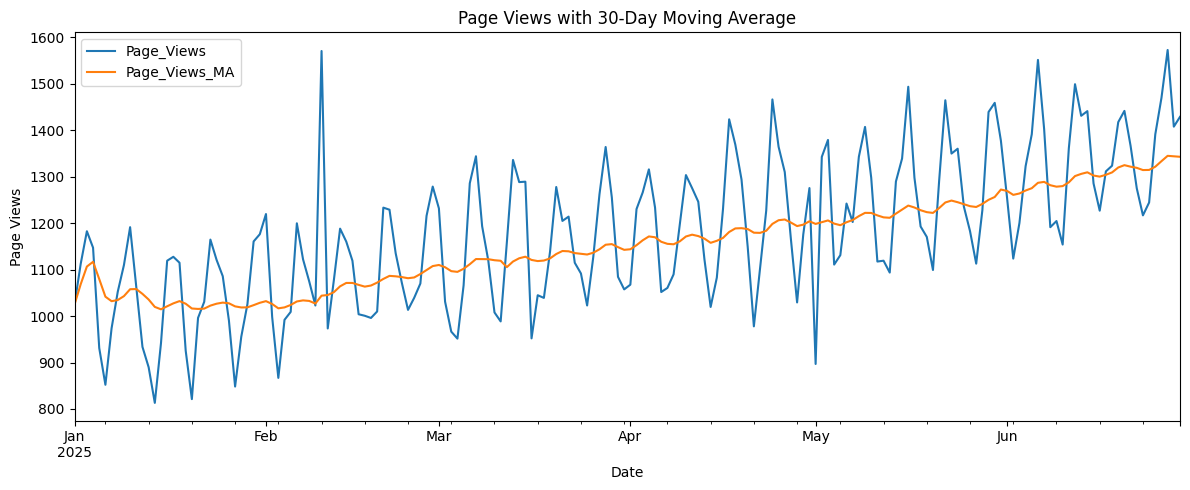

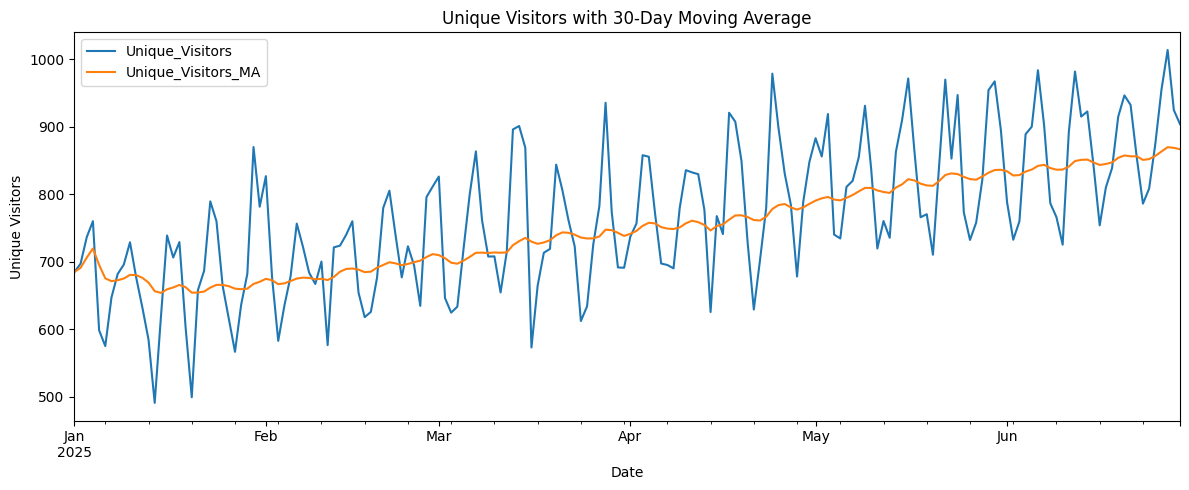

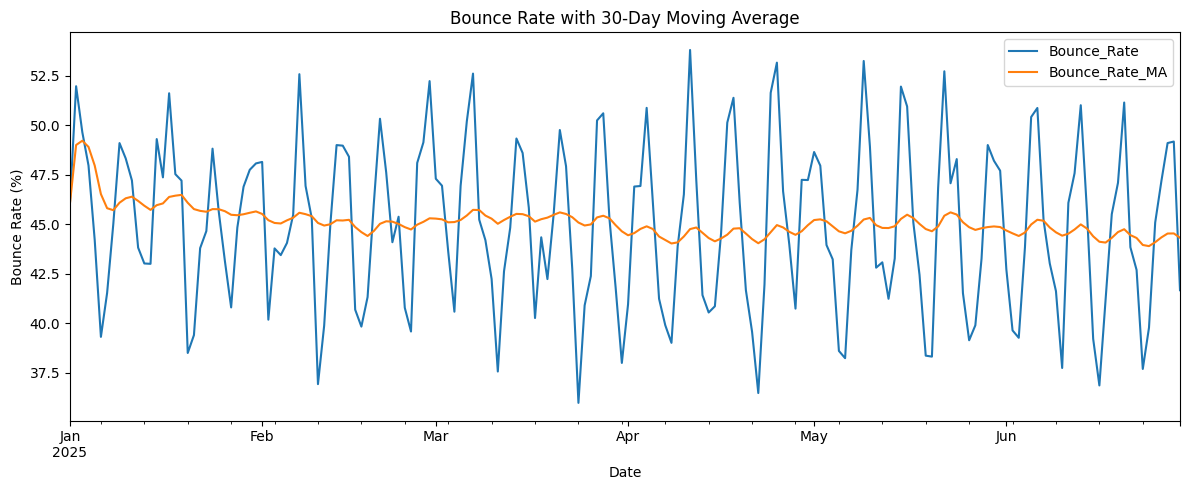

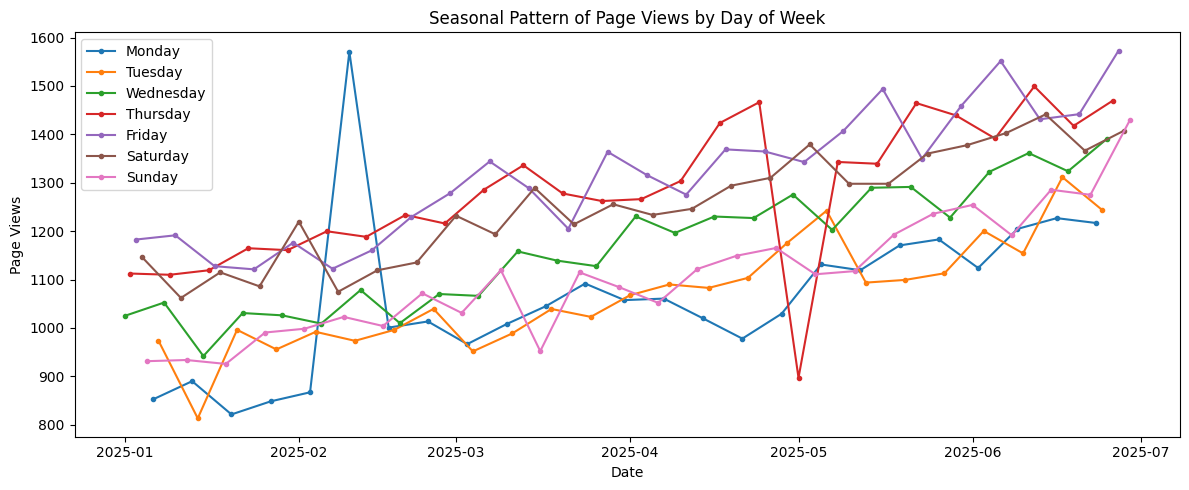


Detected Anomalies:
No anomalies detected using the Z-score threshold.


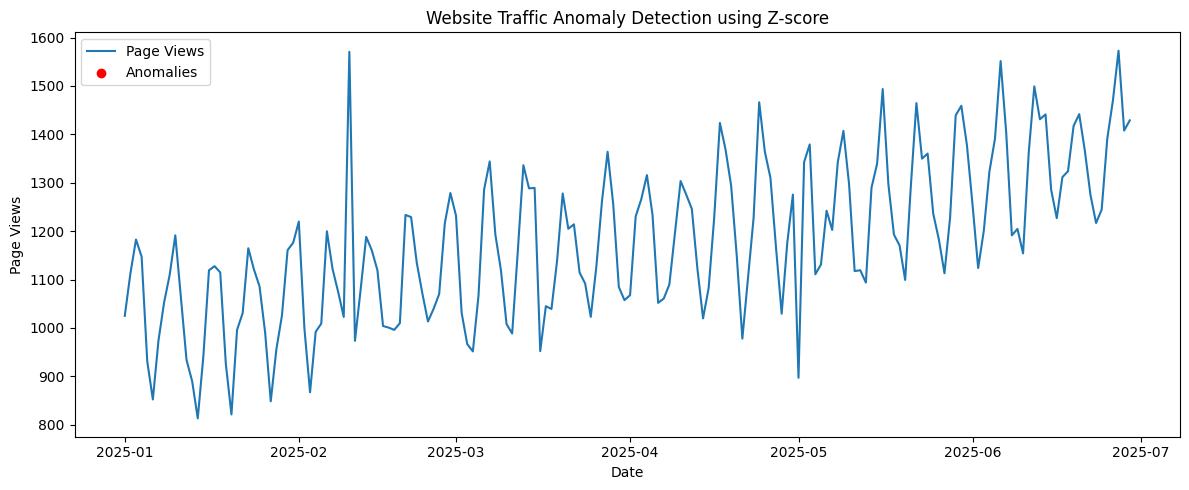


Expected Outcomes:
1. Visualized website traffic trends and patterns.
2. Identified trend, seasonality, and residual components.
3. Used moving averages to highlight long-term trends.
4. Detected unusual page-view values using the Z-score method.

Experiment 6 completed successfully!
Dataset shape: (180, 8)
Number of anomalies detected: 0


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Step 2: Create a sample website traffic dataset
# This avoids errors if website_traffic.csv is not uploaded.

np.random.seed(42)

dates = pd.date_range(start='2025-01-01', periods=180, freq='D')
day = np.arange(180)

page_views = (
    1000
    + 2 * day
    + 150 * np.sin(2 * np.pi * day / 7)
    + np.random.normal(0, 50, 180)
)

unique_visitors = (
    page_views * 0.65
    + np.random.normal(0, 30, 180)
)

bounce_rate = (
    45
    + 5 * np.sin(2 * np.pi * day / 7)
    + np.random.normal(0, 2, 180)
)

data = pd.DataFrame({
    'Date': dates,
    'Page_Views': page_views,
    'Unique_Visitors': unique_visitors,
    'Bounce_Rate': bounce_rate
})

# Add two unusual page-view values for anomaly demonstration
data.loc[40, 'Page_Views'] += 600
data.loc[120, 'Page_Views'] -= 500

# Save the sample dataset
data.to_csv('website_traffic.csv', index=False)

# Step 3: Load the dataset and parse dates
data = pd.read_csv(
    'website_traffic.csv',
    parse_dates=['Date'],
    index_col='Date'
)

print("First five rows:")
print(data.head())

# Step 4: Explore the dataset
print("\nDataset Information:")
data.info()

print("\nDataset Shape:")
print(data.shape)

print("\nMissing Values:")
print(data.isnull().sum())

print("\nStatistical Summary:")
print(data.describe())

# Step 5: Handle missing values using interpolation
data = data.interpolate(method='time')

# Step 6: Plot the time series data
data[['Page_Views', 'Unique_Visitors', 'Bounce_Rate']].plot(
    subplots=True,
    figsize=(12, 9),
    title=[
        'Daily Page Views',
        'Daily Unique Visitors',
        'Daily Bounce Rate'
    ]
)

plt.tight_layout()
plt.show()

# Step 7: Time Series Decomposition
decomposition = seasonal_decompose(
    data['Page_Views'],
    model='additive',
    period=7
)

decomposition.plot()
plt.suptitle('Time Series Decomposition of Page Views', y=1.02)
plt.tight_layout()
plt.show()

# Step 8: Calculate 30-day moving averages
data['Page_Views_MA'] = data['Page_Views'].rolling(
    window=30, min_periods=1
).mean()

data['Unique_Visitors_MA'] = data['Unique_Visitors'].rolling(
    window=30, min_periods=1
).mean()

data['Bounce_Rate_MA'] = data['Bounce_Rate'].rolling(
    window=30, min_periods=1
).mean()

# Plot Page Views and Moving Average
data[['Page_Views', 'Page_Views_MA']].plot(figsize=(12, 5))
plt.title('Page Views with 30-Day Moving Average')
plt.xlabel('Date')
plt.ylabel('Page Views')
plt.tight_layout()
plt.show()

# Plot Unique Visitors and Moving Average
data[['Unique_Visitors', 'Unique_Visitors_MA']].plot(figsize=(12, 5))
plt.title('Unique Visitors with 30-Day Moving Average')
plt.xlabel('Date')
plt.ylabel('Unique Visitors')
plt.tight_layout()
plt.show()

# Plot Bounce Rate and Moving Average
data[['Bounce_Rate', 'Bounce_Rate_MA']].plot(figsize=(12, 5))
plt.title('Bounce Rate with 30-Day Moving Average')
plt.xlabel('Date')
plt.ylabel('Bounce Rate (%)')
plt.tight_layout()
plt.show()

# Step 9: Seasonal plot by day of the week
data['Day_of_Week'] = data.index.day_name()

weekday_order = [
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
]

plt.figure(figsize=(12, 5))

for weekday in weekday_order:
    subset = data[data['Day_of_Week'] == weekday]
    plt.plot(
        subset.index,
        subset['Page_Views'],
        marker='o',
        markersize=3,
        label=weekday
    )

plt.title('Seasonal Pattern of Page Views by Day of Week')
plt.xlabel('Date')
plt.ylabel('Page Views')
plt.legend()
plt.tight_layout()
plt.show()

# Step 10: Anomaly Detection using Z-score
mean_value = data['Page_Views'].mean()
std_value = data['Page_Views'].std()

data['Page_Views_Z'] = (
    (data['Page_Views'] - mean_value) / std_value
)

anomalies = data[data['Page_Views_Z'].abs() > 3]

print("\nDetected Anomalies:")
if anomalies.empty:
    print("No anomalies detected using the Z-score threshold.")
else:
    print(anomalies[['Page_Views', 'Page_Views_Z']])

# Step 11: Visualize anomalies
plt.figure(figsize=(12, 5))

plt.plot(
    data.index,
    data['Page_Views'],
    label='Page Views'
)

plt.scatter(
    anomalies.index,
    anomalies['Page_Views'],
    color='red',
    label='Anomalies',
    zorder=3
)

plt.title('Website Traffic Anomaly Detection using Z-score')
plt.xlabel('Date')
plt.ylabel('Page Views')
plt.legend()
plt.tight_layout()
plt.show()

# Step 12: Expected Outcomes
print("\nExpected Outcomes:")
print("1. Visualized website traffic trends and patterns.")
print("2. Identified trend, seasonality, and residual components.")
print("3. Used moving averages to highlight long-term trends.")
print("4. Detected unusual page-view values using the Z-score method.")

print("\nExperiment 6 completed successfully!")
print("Dataset shape:", data.shape)
print("Number of anomalies detected:", len(anomalies))
